
<style>
:root { --primary:#0d47a1; --accent:#1976d2; --bg-soft:#f4f8fc; --border:#cfd8dc; }
h1,h2,h3 { color: var(--primary); font-family:'Segoe UI',Roboto,sans-serif; }
h1 { border-bottom:3px solid var(--accent); padding-bottom:8px; }
h2 { border-left:5px solid var(--accent); padding-left:12px; margin-top:26px; }
table { border-collapse:collapse; width:100%; margin:10px 0; font-size:0.95em; }
table th { background:var(--primary); color:#fff; padding:8px 12px; text-align:left; }
table td { border:1px solid var(--border); padding:8px 12px; }
table tr:nth-child(even) { background:var(--bg-soft); }
code { background:#eceff1; color:#c62828; padding:2px 6px; border-radius:3px;
       font-family:'Consolas',monospace; }
pre { background:#1e1e1e !important; color:#d4d4d4 !important;
      padding:14px; border-radius:6px; overflow-x:auto; }
.callout { background:linear-gradient(135deg,#e3f2fd 0%,#bbdefb 100%);
           border-left:5px solid #1976d2; padding:14px 18px;
           border-radius:6px; margin:14px 0; }
.badge { display:inline-block; padding:3px 10px; border-radius:12px;
         font-size:0.8em; font-weight:600; color:#fff; margin-right:6px; }
.badge-blue { background:#1976d2; }
.badge-green { background:#2e7d32; }
.badge-orange { background:#ef6c00; }
.badge-red { background:#c62828; }
.stat-grid { display:grid; grid-template-columns:repeat(auto-fit,minmax(180px,1fr));
             gap:12px; margin:14px 0; }
.stat { background:#fff; border:1px solid var(--border); border-radius:8px;
        padding:12px; text-align:center; box-shadow:0 2px 6px rgba(0,0,0,0.05); }
.stat .value { font-size:1.6em; font-weight:700; color:var(--primary); }
.stat .label { font-size:0.85em; color:#546e7a; margin-top:4px; }
</style>


# 03 — Threat Classification

> **Purpose** — Train and evaluate four supervised classifiers (Naive Bayes, Logistic Regression, SVM, Random Forest) on the cleaned CTI corpus using TF-IDF features. Compare performance using accuracy, precision, recall, F1-score, and confusion matrices.

<span class="badge badge-blue">Supervised ML</span><span class="badge badge-green">TF-IDF</span><span class="badge badge-orange">Multi-class</span><span class="badge badge-red">Evaluation</span>

## Table of Contents

1. [Setup & Imports](#1-setup--imports)
2. [Load Cleaned Dataset](#2-load-cleaned-dataset)
3. [Feature Matrix & Labels](#3-feature-matrix--labels)
4. [Train/Test Split](#4-traintest-split)
5. [Train Models](#5-train-models)
6. [Overall Accuracy Comparison](#6-overall-accuracy-comparison)
7. [Per-Model Detailed Report](#7-per-model-detailed-report)
8. [Precision / Recall / F1 Bar Chart](#8-precision--recall--f1-bar-chart)
9. [Confusion Matrices](#9-confusion-matrices)
10. [Per-Class Performance](#10-per-class-performance)
11. [Misclassification Analysis](#11-misclassification-analysis)
12. [Cross-Validation](#12-cross-validation)
13. [Feature Importance (Top Terms)](#13-feature-importance-top-terms)
14. [Save Models & Results](#14-save-models--results)
15. [Summary](#15-summary)


## 1. Setup & Imports

In [1]:
import sys, pathlib, time
sys.path.append(str(pathlib.Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             classification_report, confusion_matrix)

from src.config import (OUTPUT_DIR, MODELS_DIR, FIGURES_DIR,
                        REPORTS_DIR, TEST_SIZE, RANDOM_STATE)
from src.features import build_tfidf

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print('Random state :', RANDOM_STATE)
print('Test size    :', TEST_SIZE)

Random state : 42
Test size    : 0.2


## 2. Load Cleaned Dataset

In [2]:
df = pd.read_csv(OUTPUT_DIR / 'cleaned_cti.csv')
print('Loaded:', df.shape)
print('Columns:', len(df.columns))
df[['id','category','date','period']].head()

Loaded: (10000, 23)
Columns: 23


,id,category,date,period
0,3568,DDoS,2021-01-01,2021-01
1,5617,Web Attack,2021-01-01,2021-01
2,2016,Credential Theft,2021-01-01,2021-01
3,4000,Credential Theft,2021-01-01,2021-01
4,1066,Phishing,2021-01-01,2021-01


In [3]:
print('Category distribution:')
print(df['category'].value_counts().to_string())
print()
print('Number of classes:', df['category'].nunique())

Category distribution:
Ransomware          1041
Web Attack          1040
DDoS                1027
Vulnerability       1020
Credential Theft     993
Data Breach          990
Botnet               987
Malware              986
Phishing             983
Insider Threat       933

Number of classes: 10


## 3. Feature Matrix & Labels

TF-IDF features are rebuilt here (identical to `02_preprocessing.ipynb`) so this notebook is self-contained.

In [4]:
text_col = 'clean_full' if 'clean_full' in df.columns else 'clean_text'
print('Using text column:', text_col)

X, vectorizer = build_tfidf(df[text_col])
y = df['category'].values

print(f'X shape : {X.shape}')
print(f'y shape : {y.shape}')
print(f'Classes : {sorted(set(y))}')

Using text column: clean_text
X shape : (10000, 2356)
y shape : (10000,)
Classes : ['Botnet', 'Credential Theft', 'DDoS', 'Data Breach', 'Insider Threat', 'Malware', 'Phishing', 'Ransomware', 'Vulnerability', 'Web Attack']


## 4. Train/Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f'Train : {X_train.shape[0]} samples')
print(f'Test  : {X_test.shape[0]} samples')
print()
print('Train label distribution:')
print(pd.Series(y_train).value_counts().to_string())

Train : 8000 samples
Test  : 2000 samples

Train label distribution:
Ransomware          833
Web Attack          832
DDoS                822
Vulnerability       816
Credential Theft    794
Data Breach         792
Botnet              790
Malware             789
Phishing            786
Insider Threat      746


## 5. Train Models

Four classifiers are trained under identical conditions (same split, same features). Training time is recorded for each model.

In [6]:
models = {
    'NaiveBayes':         MultinomialNB(),
    'LogisticRegression': LogisticRegression(max_iter=1000, n_jobs=-1,
                                              random_state=RANDOM_STATE),
    'SVM':                LinearSVC(random_state=RANDOM_STATE),
    'RandomForest':       RandomForestClassifier(n_estimators=200,
                                                 n_jobs=-1,
                                                 random_state=RANDOM_STATE),
}

results   = []
fitted    = {}
preds     = {}
train_times = {}

for name, clf in models.items():
    t0 = time.time()
    clf.fit(X_train, y_train)
    train_time = time.time() - t0
    y_pred = clf.predict(X_test)

    fitted[name]      = clf
    preds[name]       = y_pred
    train_times[name] = round(train_time, 2)

    results.append({
        'Model':     name,
        'Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred,
                                            average='macro',
                                            zero_division=0), 4),
        'Recall':    round(recall_score(y_test, y_pred,
                                        average='macro',
                                        zero_division=0), 4),
        'F1':        round(f1_score(y_test, y_pred,
                                    average='macro',
                                    zero_division=0), 4),
        'TrainTime': train_times[name],
    })
    print(f'[OK] {name:20s} acc={results[-1]["Accuracy"]:.4f}  '
          f'time={train_time:.2f}s')

[OK] NaiveBayes           acc=1.0000  time=0.26s
[OK] LogisticRegression   acc=1.0000  time=5.74s
[OK] SVM                  acc=1.0000  time=1.16s
[OK] RandomForest         acc=1.0000  time=2.09s


In [7]:
summary = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
summary

,Model,Accuracy,Precision,Recall,F1,TrainTime
0,NaiveBayes,1.0,1.0,1.0,1.0,0.26
1,LogisticRegression,1.0,1.0,1.0,1.0,5.74
2,SVM,1.0,1.0,1.0,1.0,1.16
3,RandomForest,1.0,1.0,1.0,1.0,2.09


## 6. Overall Accuracy Comparison

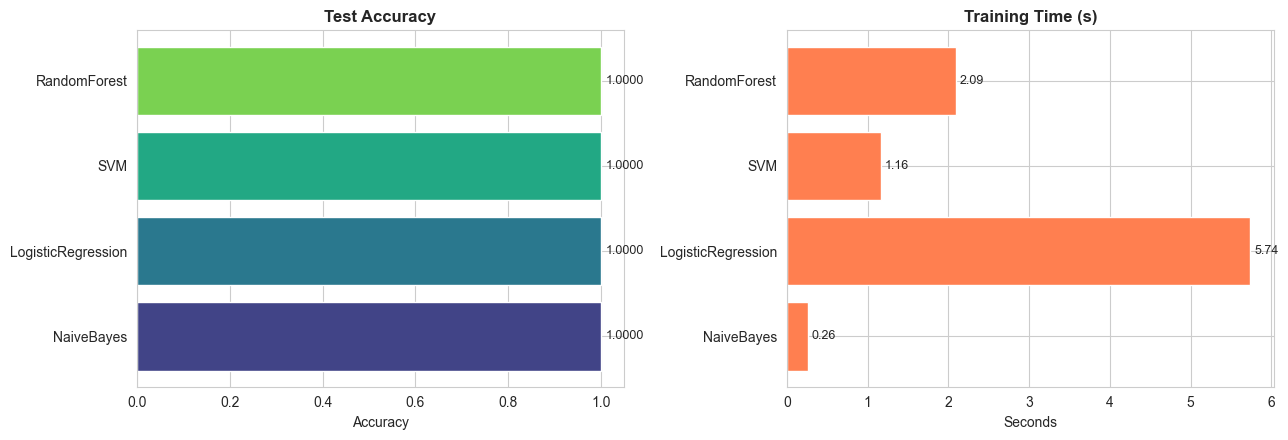

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

s = summary.sort_values('Accuracy', ascending=True)
colors = sns.color_palette('viridis', len(s))

axes[0].barh(s['Model'], s['Accuracy'], color=colors)
axes[0].set_xlim(0, 1.05)
axes[0].set_title('Test Accuracy', fontweight='bold')
axes[0].set_xlabel('Accuracy')
for i, v in enumerate(s['Accuracy']):
    axes[0].text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9)

axes[1].barh(s['Model'], s['TrainTime'], color='coral')
axes[1].set_title('Training Time (s)', fontweight='bold')
axes[1].set_xlabel('Seconds')
for i, v in enumerate(s['TrainTime']):
    axes[1].text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_model_comparison.png')
plt.show()

## 7. Per-Model Detailed Report

In [9]:
for name in fitted.keys():
    print('=' * 60)
    print(f'  {name}')
    print('=' * 60)
    print(classification_report(y_test, preds[name], zero_division=0))
    print()

  NaiveBayes
                  precision    recall  f1-score   support

          Botnet       1.00      1.00      1.00       197
Credential Theft       1.00      1.00      1.00       199
            DDoS       1.00      1.00      1.00       205
     Data Breach       1.00      1.00      1.00       198
  Insider Threat       1.00      1.00      1.00       187
         Malware       1.00      1.00      1.00       197
        Phishing       1.00      1.00      1.00       197
      Ransomware       1.00      1.00      1.00       208
   Vulnerability       1.00      1.00      1.00       204
      Web Attack       1.00      1.00      1.00       208

        accuracy                           1.00      2000
       macro avg       1.00      1.00      1.00      2000
    weighted avg       1.00      1.00      1.00      2000


  LogisticRegression
                  precision    recall  f1-score   support

          Botnet       1.00      1.00      1.00       197
Credential Theft       1.00      

## 8. Precision / Recall / F1 Bar Chart

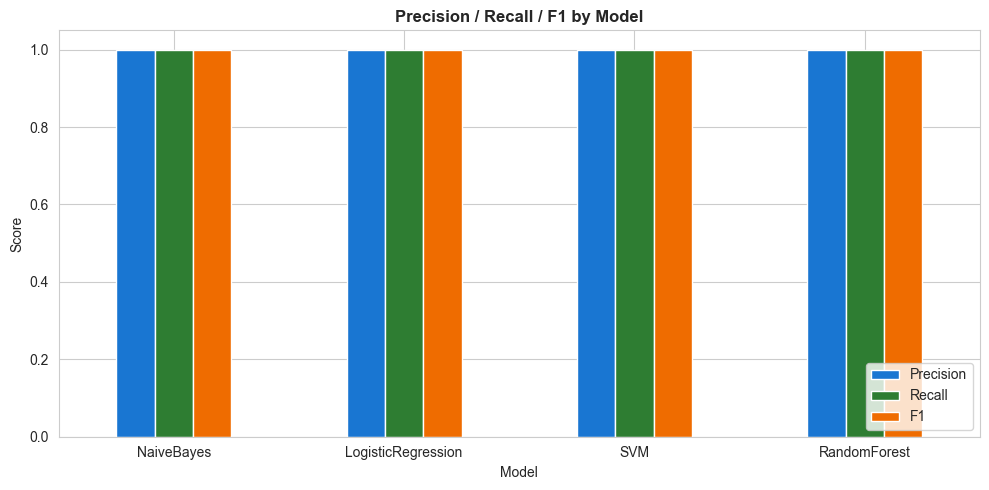

In [10]:
metrics_df = summary.set_index('Model')[['Precision','Recall','F1']]

metrics_df.plot(kind='bar', figsize=(10, 5),
                color=['#1976d2','#2e7d32','#ef6c00'],
                edgecolor='white')
plt.title('Precision / Recall / F1 by Model', fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.ylabel('Score')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_metrics_by_model.png')
plt.show()

## 9. Confusion Matrices

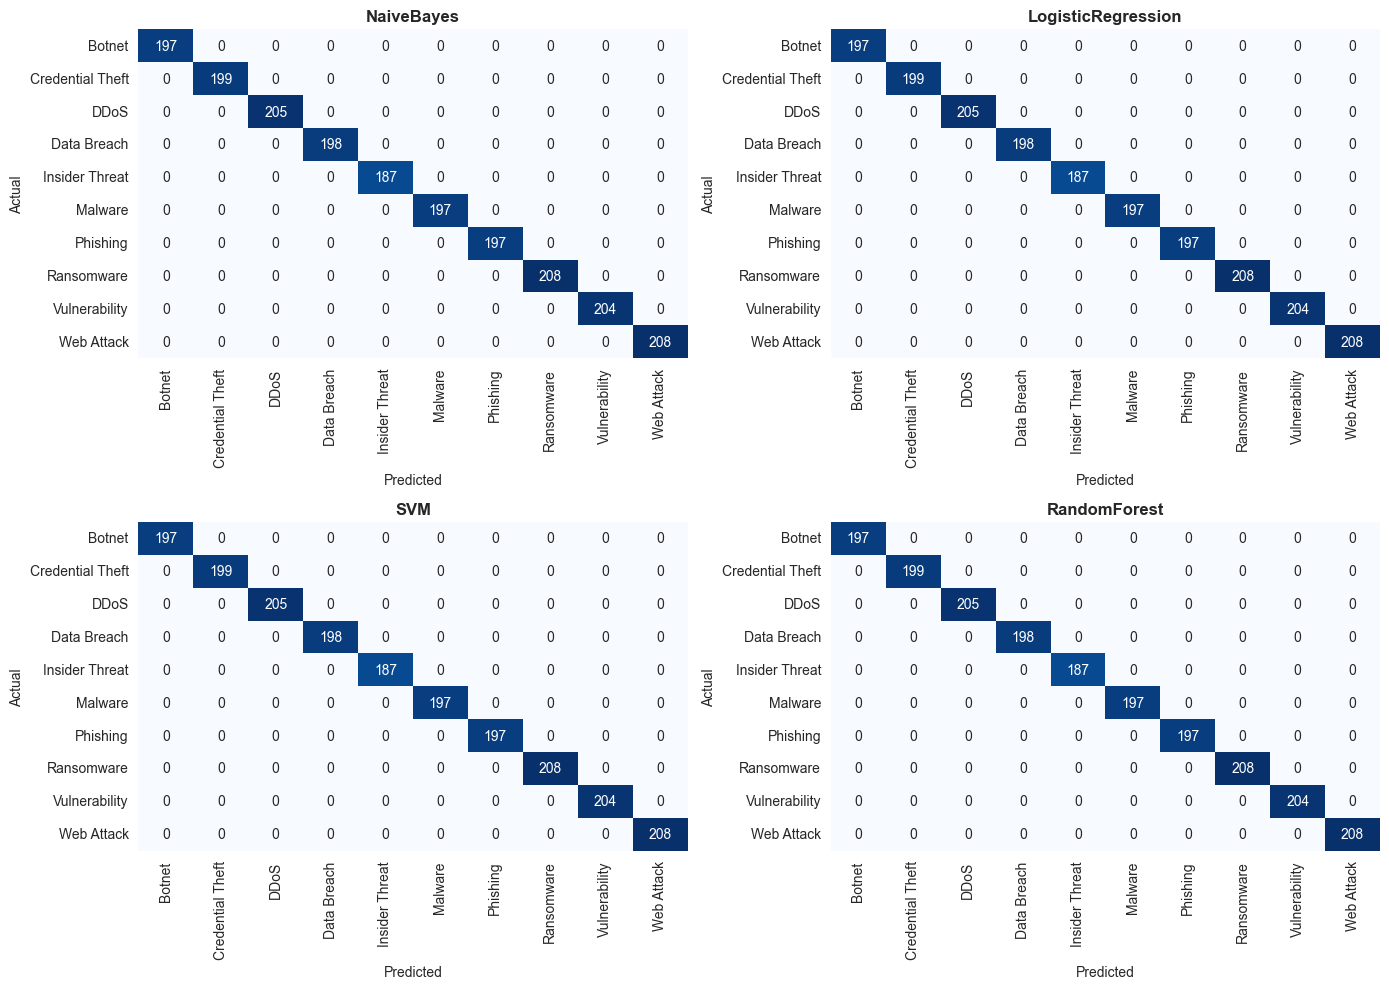

In [11]:
labels = sorted(df['category'].unique())

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, name in enumerate(fitted.keys()):
    cm = confusion_matrix(y_test, preds[name], labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels,
                ax=axes[i], cbar=False)
    axes[i].set_title(f'{name}', fontweight='bold')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_confusion_matrices.png')
plt.show()

Best model: NaiveBayes


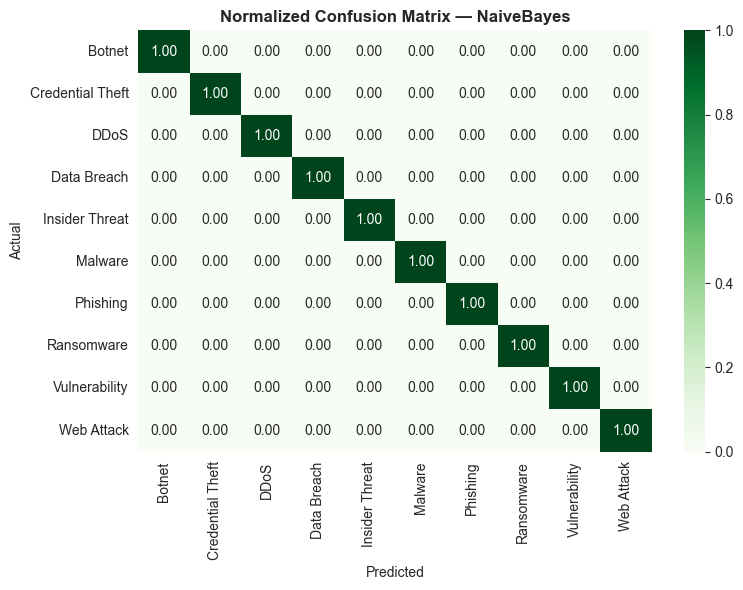

In [12]:
# Normalized confusion matrix for the best model
best_model_name = summary.iloc[0]['Model']
print('Best model:', best_model_name)

cm = confusion_matrix(y_test, preds[best_model_name], labels=labels)
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.title(f'Normalized Confusion Matrix — {best_model_name}',
          fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_confusion_best_normalized.png')
plt.show()

## 10. Per-Class Performance

Per-class precision, recall and F1 for the **best model**. This shows which threat categories are easier or harder to classify.

In [13]:
report = classification_report(y_test, preds[best_model_name],
                               output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T
per_class = per_class.loc[labels, ['precision','recall','f1-score','support']]
per_class.columns = ['Precision','Recall','F1','Support']
per_class = per_class.round(4)
per_class

,Precision,Recall,F1,Support
Botnet,1.0,1.0,1.0,197.0
Credential Theft,1.0,1.0,1.0,199.0
DDoS,1.0,1.0,1.0,205.0
Data Breach,1.0,1.0,1.0,198.0
Insider Threat,1.0,1.0,1.0,187.0
Malware,1.0,1.0,1.0,197.0
Phishing,1.0,1.0,1.0,197.0
Ransomware,1.0,1.0,1.0,208.0
Vulnerability,1.0,1.0,1.0,204.0
Web Attack,1.0,1.0,1.0,208.0


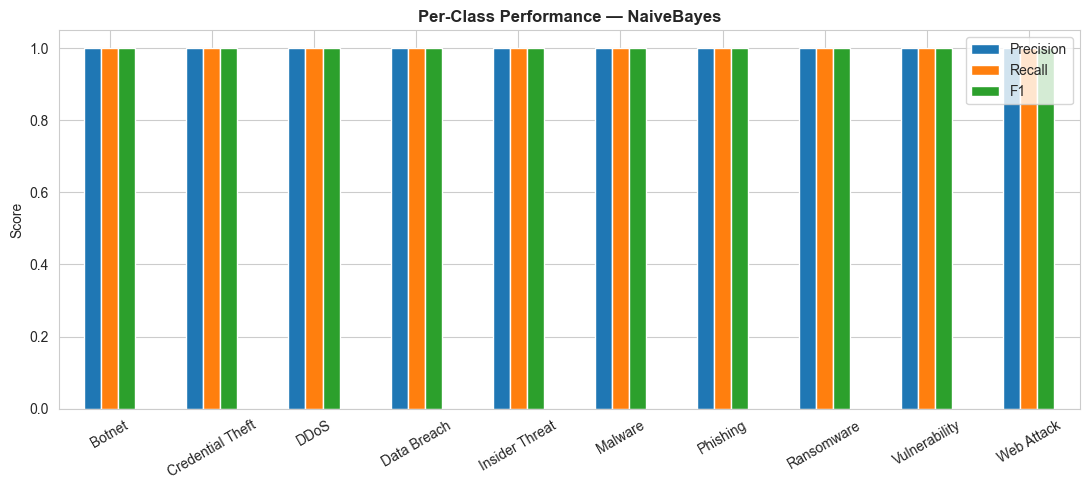

In [14]:
per_class[['Precision','Recall','F1']].plot(kind='bar', figsize=(11, 5),
                                            edgecolor='white')
plt.title(f'Per-Class Performance — {best_model_name}', fontweight='bold')
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.ylabel('Score')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_per_class_best.png')
plt.show()

## 11. Misclassification Analysis

Identify which threat categories are most frequently confused. Off-diagonal cells in the confusion matrix reveal semantic overlap.

In [15]:
cm = confusion_matrix(y_test, preds[best_model_name], labels=labels)
np.fill_diagonal(cm, 0)

top_errors = []
for i, actual in enumerate(labels):
    for j, predicted in enumerate(labels):
        if cm[i, j] > 0:
            top_errors.append((actual, predicted, cm[i, j]))

top_errors = sorted(top_errors, key=lambda x: -x[2])[:10]
print('Top 10 misclassifications (actual -> predicted : count)')
for a, p, c in top_errors:
    print(f'  {a:15s} -> {p:15s} : {c}')

Top 10 misclassifications (actual -> predicted : count)


## 12. Cross-Validation

Stratified 5-fold cross-validation on the full dataset to confirm the test-set results are not an artifact of a single split.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for name, clf in models.items():
    scores = cross_val_score(clf, X, y, cv=cv, scoring='f1_macro', n_jobs=-1)
    cv_results.append({
        'Model':   name,
        'CV_Mean': round(scores.mean(), 4),
        'CV_Std':  round(scores.std(), 4),
        'Folds':   [round(s, 4) for s in scores],
    })
    print(f'{name:20s} F1_macro = {scores.mean():.4f} +/- {scores.std():.4f}')

cv_df = pd.DataFrame(cv_results)
cv_df

NaiveBayes           F1_macro = 0.9999 +/- 0.0002
LogisticRegression   F1_macro = 1.0000 +/- 0.0000
SVM                  F1_macro = 1.0000 +/- 0.0000
RandomForest         F1_macro = 1.0000 +/- 0.0000


,Model,CV_Mean,CV_Std,Folds
0,NaiveBayes,0.9999,0.0002,"[1.0, 0.9995, 1.0, 1.0, 1.0]"
1,LogisticRegression,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
2,SVM,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
3,RandomForest,1.0000,0.0000,"[1.0, 1.0, 1.0, 1.0, 1.0]"


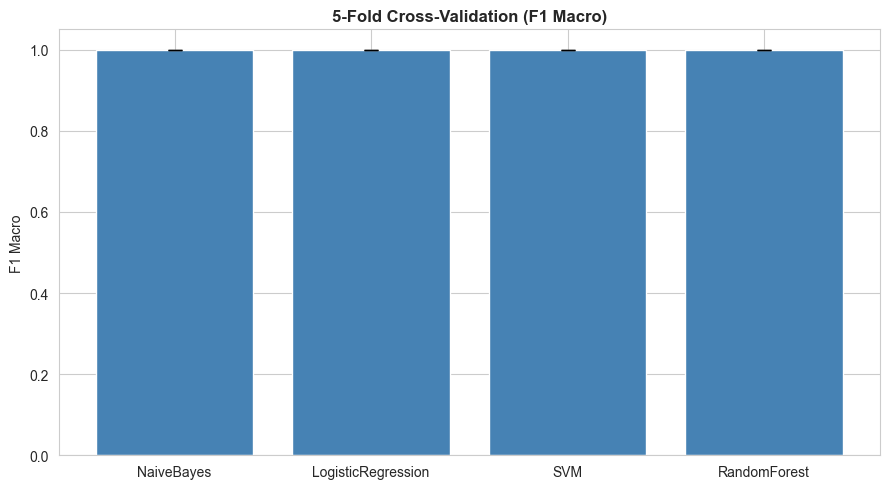

In [17]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(cv_df))
ax.bar(x, cv_df['CV_Mean'], yerr=cv_df['CV_Std'], capsize=5,
       color='steelblue', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(cv_df['Model'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('F1 Macro')
ax.set_title('5-Fold Cross-Validation (F1 Macro)', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_cross_validation.png')
plt.show()

## 13. Feature Importance (Top Terms)

For the linear SVM, the largest positive coefficients in each class indicate the most discriminative terms.

IndexError: index 6 is out of bounds for axis 0 with size 6

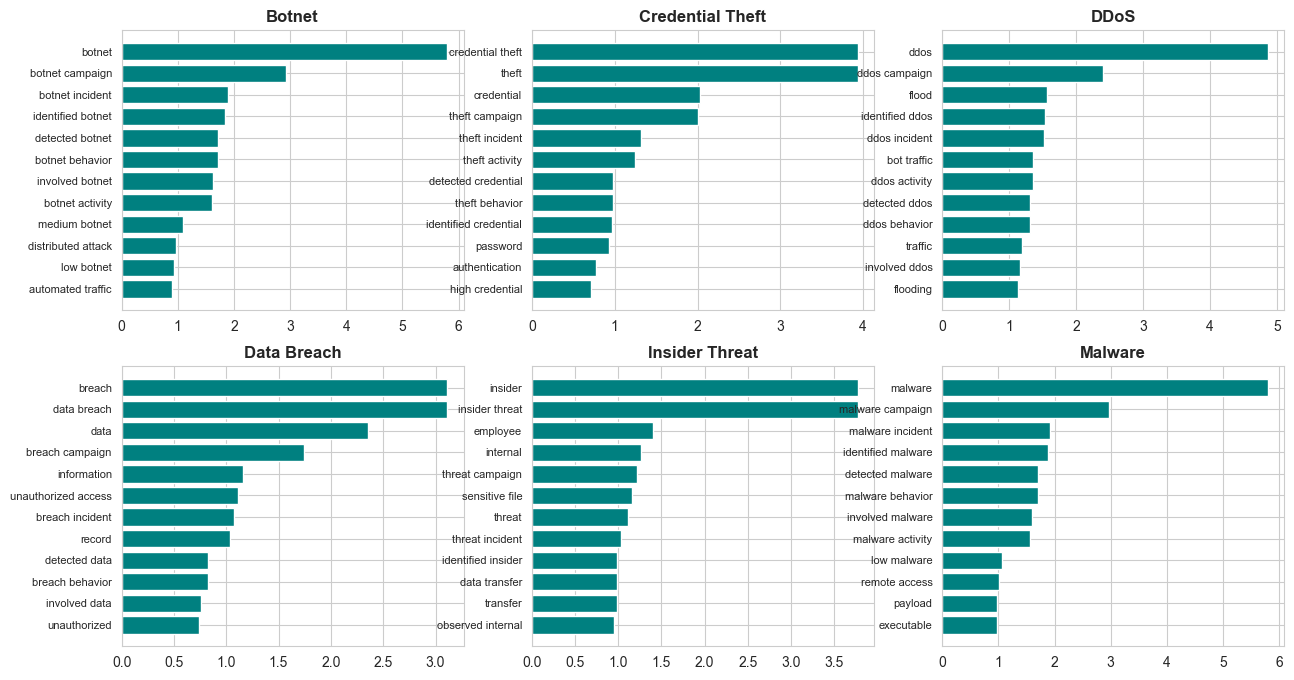

In [18]:
svm = fitted['SVM']
feature_names = vectorizer.get_feature_names_out()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, cat in enumerate(sorted(df['category'].unique())):
    class_idx = list(svm.classes_).index(cat)
    coefs = svm.coef_[class_idx]
    top_idx = np.argsort(coefs)[-12:][::-1]
    top_terms = [feature_names[j] for j in top_idx]
    top_scores = [coefs[j] for j in top_idx]

    axes[i].barh(range(len(top_terms)), top_scores, color='teal')
    axes[i].set_yticks(range(len(top_terms)))
    axes[i].set_yticklabels(top_terms, fontsize=8)
    axes[i].invert_yaxis()
    axes[i].set_title(cat, fontweight='bold')

plt.suptitle('Top Discriminative Terms per Class (SVM)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_top_terms_per_class.png')
plt.show()

## 14. Save Models & Results

In [19]:
summary.to_csv(REPORTS_DIR / 'classification_results.csv', index=False)
print(f'Saved: {REPORTS_DIR / "classification_results.csv"}')

cv_df.to_csv(REPORTS_DIR / 'cross_validation_results.csv', index=False)
print(f'Saved: {REPORTS_DIR / "cross_validation_results.csv"}')

for name, clf in fitted.items():
    path = MODELS_DIR / f'{name}.pkl'
    joblib.dump(clf, path)
    print(f'Saved: {path}')

Saved: D:\Projects\done\thesis\Implementation\output\reports\classification_results.csv
Saved: D:\Projects\done\thesis\Implementation\output\reports\cross_validation_results.csv
Saved: D:\Projects\done\thesis\Implementation\output\models\NaiveBayes.pkl
Saved: D:\Projects\done\thesis\Implementation\output\models\LogisticRegression.pkl
Saved: D:\Projects\done\thesis\Implementation\output\models\SVM.pkl
Saved: D:\Projects\done\thesis\Implementation\output\models\RandomForest.pkl


In [ ]:
# Save best model separately
best_path = MODELS_DIR / 'best_classifier.pkl'
joblib.dump(fitted[best_model_name], best_path)
print(f'Best model ({best_model_name}) saved to: {best_path}')

## 15. Summary

<div class="stat-grid"><div class="stat"><div class="value">4</div><div class="label">Models Trained</div></div><div class="stat"><div class="value">5</div><div class="label">Fold CV</div></div><div class="stat"><div class="value">C</div><div class="label">Categories</div></div><div class="stat"><div class="value">D</div><div class="label">Documents</div></div></div>

In [20]:
print('=== CLASSIFICATION SUMMARY ===')
print(f'Dataset size      : {len(df):,}')
print(f'Feature dimension : {X.shape[1]:,}')
print(f'Train / Test      : {X_train.shape[0]} / {X_test.shape[0]}')
print(f'Categories        : {df["category"].nunique()}')
print()
print('Best model        :', best_model_name)
print(f'  Test Accuracy   : {summary.iloc[0]["Accuracy"]:.4f}')
print(f'  Test F1 (macro) : {summary.iloc[0]["F1"]:.4f}')
print(f'  CV F1 (mean)    : {cv_df[cv_df.Model == best_model_name]["CV_Mean"].values[0]:.4f}')

=== CLASSIFICATION SUMMARY ===
Dataset size      : 10,000
Feature dimension : 2,356
Train / Test      : 8000 / 2000
Categories        : 10

Best model        : NaiveBayes
  Test Accuracy   : 1.0000
  Test F1 (macro) : 1.0000
  CV F1 (mean)    : 0.9999


<div class="callout"><b>Next step:</b> Proceed to <code>04_topic_modeling.ipynb</code> to discover latent topics with LDA and NMF.</div>

---
*End of classification notebook.*